---

# Implementación en reglas del proyecto <a class="anchor" id="comp"></a>

In [1]:
import os, sys, time
import pandas as pd
from itertools import product
from logica import *
from problema import CicloHamiltoniano

sys.setrecursionlimit(10000)   # las reglas son fórmulas largas (recursión profunda)
os.makedirs('resultados', exist_ok=True)

# SATtabla tal como la implementamos en el taller (recorre las interpretaciones una a una,
# sin construir la lista completa de 2^25 interpretaciones en memoria)
def SATtabla(self):
    letras = list(self.letras())
    for valores in product([True, False], repeat=len(letras)):
        I = dict(zip(letras, valores))
        if self.valor(I):
            return I
    return None

setattr(Formula, "SATtabla", SATtabla)

ciudades = ['Baq', 'Buc', 'Bog', 'Med', 'Per']
aristas  = [{0,1}, {1,2}, {2,3}, {3,4}, {2,4}, {0,2}, {1,4}]
coords   = {0:(0,3), 1:(3,3), 2:(1.5,1.8), 3:(0.3,0), 4:(2.7,0)}   # solo para dibujar

H = CicloHamiltoniano(ciudades, aristas, coords)
print('Letras proposicionales:', H.n * H.n)

# --- Registro de resultados (alimenta la tabla resumen del final) ---
SOLVER = 'SATtabla'
resultados = {}

def registrar(nombre, A, I, seg):
    '''Guarda una fila de la tabla resumen y la imprime.
    I puede ser parcial (otros solvers): se completan con False las letras que falten.'''
    if I:
        J = {l: False for l in A.letras()}
        J.update(I)
        verifica = A.valor(J)
    else:
        verifica = None
    resultados[nombre] = {'Solver': SOLVER, 'Regla': nombre,
                          'Resultado': 'modelo' if I else 'sin modelo',
                          '¿Verifica?': verifica,
                          'Tiempo (s)': round(seg, 3),
                          'Modelo':I}
    print(f'{nombre}:', resultados[nombre]['Resultado'], '| ¿verifica?', verifica, f'| {seg:.3f} s')

Letras proposicionales: 25


**Regla 1**

In [2]:
%%time
A = inorder_to_tree(H.reglas[0])
t0 = time.perf_counter()
I = A.SATtabla()
registrar('Regla 1', A, I, time.perf_counter() - t0)

Regla 1: modelo | ¿verifica? True | 0.000 s
CPU times: user 148 µs, sys: 60 µs, total: 208 µs
Wall time: 208 µs


**Regla 2**

In [3]:
%%time
A = inorder_to_tree(H.reglas[1])
t0 = time.perf_counter()
I = A.SATtabla()
registrar('Regla 2', A, I, time.perf_counter() - t0)

Regla 2: modelo | ¿verifica? True | 0.000 s
CPU times: user 156 µs, sys: 91 µs, total: 247 µs
Wall time: 471 µs


**Regla 3**

In [4]:
%%time
A = inorder_to_tree(H.reglas[2])
t0 = time.perf_counter()
I = A.SATtabla()
registrar('Regla 3', A, I, time.perf_counter() - t0)

Regla 3: modelo | ¿verifica? True | 14.316 s
CPU times: user 14.1 s, sys: 68.5 ms, total: 14.2 s
Wall time: 14.3 s


**Regla 4**

In [5]:
%%time
A = inorder_to_tree(H.reglas[3])
t0 = time.perf_counter()
I = A.SATtabla()
registrar('Regla 4', A, I, time.perf_counter() - t0)

Regla 4: modelo | ¿verifica? True | 0.000 s
CPU times: user 446 µs, sys: 67 µs, total: 513 µs
Wall time: 513 µs


**Regla 5**

In [6]:
%%time
A = inorder_to_tree(H.reglas[4])
t0 = time.perf_counter()
I = A.SATtabla()
registrar('Regla 5', A, I, time.perf_counter() - t0)

Regla 5: modelo | ¿verifica? True | 0.000 s
CPU times: user 107 µs, sys: 11 µs, total: 118 µs
Wall time: 118 µs


## Las cinco reglas juntas

In [7]:
%%time
A = inorder_to_tree(Ytoria(H.reglas))
t0 = time.perf_counter()
I = A.SATtabla()
registrar('Reglas 1 a 5', A, I, time.perf_counter() - t0)

Reglas 1 a 5: modelo | ¿verifica? True | 79.927 s
CPU times: user 1min 18s, sys: 615 ms, total: 1min 18s
Wall time: 1min 19s


### Visualización de la solución

El modelo que devuelve SATtabla es un ciclo hamiltoniano. Lo dibujamos con nuestro visualizador por turnos:

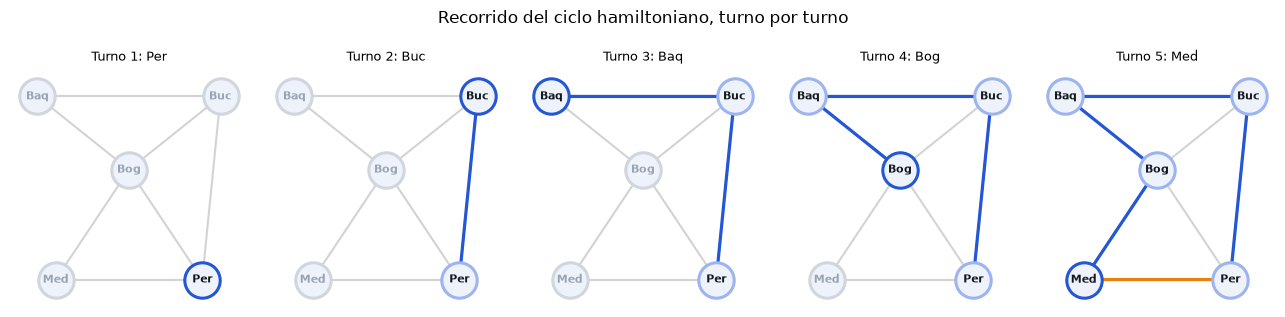

In [11]:
if I:
    H.visualizar_por_turnos(I)

## Tabla resumen

Reúne las filas registradas arriba. Si vuelves a correr una celda, su fila se actualiza (no se duplica). La guardamos en un CSV para poder juntarla después con la de los otros SAT-solvers.

In [9]:
tabla = pd.DataFrame([{k: v for k, v in fila.items() if k != 'Modelo'}      # el modelo va al JSON, no al CSV
                      for fila in resultados.values()])
tabla.to_csv(f'resultados/resultados_{SOLVER}.csv', index=False)
tabla

,Solver,Regla,Resultado,¿Verifica?,Tiempo (s)
0,SATtabla,Regla 1,modelo,True,0.000
1,SATtabla,Regla 2,modelo,True,0.000
2,SATtabla,Regla 3,modelo,True,14.316
3,SATtabla,Regla 4,modelo,True,0.000
4,SATtabla,Regla 5,modelo,True,0.000
5,SATtabla,Reglas 1 a 5,modelo,True,79.927


## Modelos a JSON

Igual que en los otros notebooks (`Tableaux`, y más adelante `WalkSAT` y `DPLL`),
guardamos los modelos encontrados en un archivo JSON con la misma estructura,
para poder juntarlos todos al final en `resultados/modelos_TODOS.json`.


In [10]:
import json

modelos_SATtabla = {'SATtabla': {}}
for nombre, fila in resultados.items():
    modelos_SATtabla['SATtabla'][nombre] = {
        'resultado': fila['Resultado'],
        'verifica':  fila['¿Verifica?'],
        'tiempo_s':  fila['Tiempo (s)'],
        'modelo':    fila.get('Modelo'),   # ← ojo: ver abajo
    }

with open('resultados/modelos_SATtabla.json', 'w', encoding='utf-8') as f:
    json.dump(modelos_SATtabla, f, ensure_ascii=False, indent=2)

print('Guardado resultados/modelos_SATtabla.json')
for regla, datos in modelos_SATtabla['SATtabla'].items():
    print(f'  {regla:14s} → modelo: {datos["modelo"] is not None}')

Guardado resultados/modelos_SATtabla.json
  Regla 1        → modelo: True
  Regla 2        → modelo: True
  Regla 3        → modelo: True
  Regla 4        → modelo: True
  Regla 5        → modelo: True
  Reglas 1 a 5   → modelo: True
